# Similarity Analysis

Analisa a base mista e compartilha os mesmos dados finais entre Mahalanobis e PCA.


In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

from src.Similarity.Preprocessing import SimilarityPreprocessor
from src.Similarity.OneVsAll import SimilarityOneVsAll
from src.Similarity.SimilarityAnalyzer import SimilarityAnalyzer
from src.Plots.SimilarityDistanceHeatmapPlot import SimilarityDistanceHeatmapPlot
from src.Plots.SimilarityDendrogramPlot import SimilarityDendrogramPlot
from src.Plots.SimilaritySamples3DPlot import SimilaritySamples3DPlot
from src.Plots.SimilaritySamples2DPlot import SimilaritySamples2DPlot

datasetPath = Path("data/similarity/similarity_1s.csv")
analysisOutputDirectory = Path("output/Similarity") / datasetPath.stem
intermediateDirectory = analysisOutputDirectory / "preprocessed"
plotDataPath = analysisOutputDirectory / "mahalanobis_plot_data.npz"


## 1. Preprocessing

Limpa e imputa os dados, com exportação intermediária opcional para a pasta desta análise.


In [4]:
saveIntermediate = False
selectedFeatures = None
removedFeatures = ["FlowCount"]
nearConstantRatio = 0.999
normalization = "standard"

prepared = SimilarityPreprocessor(
    windowSeconds=1.0,
    nearConstantRatio=nearConstantRatio,
    removeZeroColumns=True,
    removeAllMissingColumns=True,
    removeConstantColumns=True,
    imputation="median",
    normalization=normalization,
).runFromFile(
    datasetPath=datasetPath,
    selectedFeatures=selectedFeatures,
    removedFeatures=removedFeatures,
    saveIntermediate=saveIntermediate, intermediateDirectory=intermediateDirectory,
)


## 2. One-vs-All

Seleciona a união do Top-K por classe usando todas as amostras preparadas.


In [5]:
featuresPerAttack = 15
nEstimators = 300
oneVsAllRandomSeed = 42
nJobs = 1

selection = SimilarityOneVsAll(
    featuresPerAttack=featuresPerAttack,
    nEstimators=nEstimators,
    randomSeed=oneVsAllRandomSeed,
    nJobs=nJobs,
).run(prepared, saveIntermediate=saveIntermediate, intermediateDirectory=intermediateDirectory)

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(selection["featureTable"])


,Class,SelectedCount,Features
0,BENIGN,15,"DestinationPortEntropy, Avg_Fwd_Segment_Size, Fwd_Packet_Length_Mean, Subflow_Fwd_Packets, UniqueDestinationPorts, Total_Fwd_Packets, SourcePortEntropy, Subflow_Fwd_Bytes, Max_Packet_Length, Total_Length_of_Fwd_Packets, Fwd_Packet_Length_Max, Average_Packet_Size, Flow_Bytes_s, UniqueSourcePorts, Packet_Length_Mean"
1,DNS,15,"Total_Length_of_Fwd_Packets, Subflow_Fwd_Bytes, act_data_pkt_fwd, Fwd_Packet_Length_Mean, Avg_Fwd_Segment_Size, Subflow_Fwd_Packets, Flow_Bytes_s, Average_Packet_Size, DestinationPortEntropy, Packet_Length_Mean, Total_Fwd_Packets, Fwd_Packet_Length_Max, Fwd_Packets_s, Max_Packet_Length, SourcePortEntropy"
2,LDAP,15,"Total_Length_of_Fwd_Packets, Subflow_Fwd_Bytes, Flow_Bytes_s, DestinationPortEntropy, act_data_pkt_fwd, Subflow_Fwd_Packets, UniqueSourcePorts, UniqueDestinationPorts, SourcePortEntropy, Total_Fwd_Packets, Packet_Length_Mean, Fwd_Packet_Length_Mean, Avg_Fwd_Segment_Size, Average_Packet_Size, Fwd_Packet_Length_Max"
3,MSSQL,15,"Avg_Fwd_Segment_Size, Total_Length_of_Fwd_Packets, Average_Packet_Size, Fwd_Packet_Length_Mean, Subflow_Fwd_Bytes, DestinationPortEntropy, Fwd_Packet_Length_Std, UniqueSourcePorts, Packet_Length_Mean, Fwd_Packet_Length_Max, Packet_Length_Variance, UniqueDestinationPorts, Flow_Bytes_s, Subflow_Fwd_Packets, Packet_Length_Std"
4,NETBIOS,15,"Avg_Fwd_Segment_Size, Fwd_Packet_Length_Mean, DestinationPortEntropy, Fwd_Packet_Length_Max, Average_Packet_Size, Max_Packet_Length, Packet_Length_Mean, act_data_pkt_fwd, Total_Length_of_Fwd_Packets, Subflow_Fwd_Bytes, Subflow_Fwd_Packets, UniqueDestinationPorts, Total_Fwd_Packets, SourcePortEntropy, Fwd_Packet_Length_Std"
5,NTP,15,"Bwd_Packets_s, min_seg_size_forward, SourceIPEntropy, Init_Win_bytes_forward, Flow_Duration, Fwd_Packet_Length_Mean, Flow_IAT_Max, Avg_Fwd_Segment_Size, Total_Length_of_Fwd_Packets, Fwd_IAT_Min, Subflow_Fwd_Bytes, Flow_Packets_s, act_data_pkt_fwd, Max_Packet_Length, CWE_Flag_Count"
6,SNMP,15,"Avg_Fwd_Segment_Size, Flow_Bytes_s, Fwd_Packet_Length_Mean, Packet_Length_Mean, Max_Packet_Length, Average_Packet_Size, Fwd_Packet_Length_Max, Flow_Duration, Fwd_Packets_s, DestinationPortEntropy, Flow_IAT_Mean, UniqueDestinationPorts, act_data_pkt_fwd, Total_Fwd_Packets, min_seg_size_forward"
7,SSDP,15,"Avg_Fwd_Segment_Size, Fwd_Packet_Length_Mean, Packet_Length_Mean, Average_Packet_Size, DestinationPortEntropy, Subflow_Fwd_Bytes, UniqueDestinationPorts, Fwd_Packet_Length_Max, Total_Length_of_Fwd_Packets, SourcePortEntropy, Bwd_Packets_s, Fwd_Packet_Length_Std, UniqueSourcePorts, Down_Up_Ratio, Flow_Bytes_s"
8,SYN,15,"ACK_Flag_Count, Total_Backward_Packets, Subflow_Bwd_Packets, Bwd_Header_Length, Fwd_Header_Length, SourcePortEntropy, UniqueDestinationPorts, DestinationPortEntropy, UniqueSourcePorts, Subflow_Fwd_Packets, Total_Fwd_Packets, Fwd_IAT_Total, Fwd_Packet_Length_Mean, Average_Packet_Size, Bwd_Packet_Length_Mean"
9,TFTP,15,"Max_Packet_Length, Fwd_Packet_Length_Max, Fwd_IAT_Std, Flow_IAT_Std, Avg_Fwd_Segment_Size, Fwd_Packets_s, Fwd_Packet_Length_Mean, Flow_Bytes_s, Packet_Length_Mean, Flow_Packets_s, Bwd_Packets_s, Fwd_IAT_Max, Flow_IAT_Mean, Flow_IAT_Max, Flow_Duration"


## 3. Covariance and Centroids

Balanceia opcionalmente, padroniza e calcula os centroides e a covariância comum de Ledoit-Wolf.


In [6]:
statisticsDownsample = "random"
statisticsRandomSeed = 42

analysis = SimilarityAnalyzer().run(
    selection=selection,
    outputDirectory=analysisOutputDirectory,
    downsample=statisticsDownsample,
    randomSeed=statisticsRandomSeed,
    saveIntermediate=saveIntermediate, intermediateDirectory=intermediateDirectory,
)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(analysis["centroids"])
    display(analysis["covariance"])


,UniqueDestinationPorts,DestinationPortEntropy,SourceIPEntropy,UniqueSourcePorts,SourcePortEntropy,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Mean,Flow_Bytes_s,Flow_Packets_s,Flow_IAT_Mean,Flow_IAT_Std,Flow_IAT_Max,Fwd_IAT_Total,Fwd_IAT_Std,Fwd_IAT_Max,Fwd_IAT_Min,Fwd_Header_Length,Bwd_Header_Length,Fwd_Packets_s,Bwd_Packets_s,Min_Packet_Length,Max_Packet_Length,Packet_Length_Mean,Packet_Length_Std,Packet_Length_Variance,ACK_Flag_Count,CWE_Flag_Count,Down_Up_Ratio,Average_Packet_Size,Avg_Fwd_Segment_Size,Subflow_Fwd_Packets,Subflow_Fwd_Bytes,Subflow_Bwd_Packets,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward
Class,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
BENIGN,-0.736938,-1.149092,0.379157,-0.609888,-0.919792,0.866218,-0.469967,-0.188010,-0.495464,-0.904677,-0.472419,-0.877493,-0.316927,0.402560,-0.414975,-0.255093,0.330606,0.410707,0.049895,-0.132346,0.458973,0.053036,0.240620,0.302357,0.040807,-0.267319,0.270427,-0.525192,0.066842,-0.749766,0.198536,0.286531,-0.304808,0.425467,0.990000,-0.761440,-0.877493,-0.469967,-0.495464,-0.188010,0.690286,0.705910,-0.304408,0.604580
DNS,0.122578,0.070962,0.027849,-0.529193,-0.371448,-0.204967,0.379528,-0.242921,0.334334,0.589245,-0.107469,0.271627,0.536746,0.008808,-0.166864,-0.176204,-0.294842,-0.318392,-0.277262,-0.133560,-0.300437,-0.272114,-0.046820,0.003757,0.040805,-0.173753,-0.067922,-0.080010,0.170870,0.270089,0.287905,0.005961,-0.305213,-0.145159,-0.354806,0.184535,0.271627,0.379528,0.334334,-0.242921,-0.286341,-0.065691,-0.088827,-0.422065
LDAP,0.219922,0.899392,-0.641279,-0.412394,0.509611,-0.262972,0.031294,-0.249503,0.396235,0.941404,0.131462,1.716440,-0.236258,-0.174304,0.772993,0.276455,-0.319408,-0.392163,-0.448832,-0.134097,-0.373764,-0.437264,-0.046822,-0.014722,0.040805,0.279991,-0.065979,0.223538,0.268157,1.700949,-0.260608,-0.095042,-0.305170,-0.211232,-0.507314,1.753167,1.716440,0.031294,0.396235,-0.249503,-0.471104,-0.201244,-0.138657,-1.083682
MSSQL,0.798392,0.652692,-0.359791,1.351928,0.702192,-0.183200,-0.006329,-0.234468,0.078208,0.766628,0.117046,0.069723,0.577998,-0.005201,-0.202732,-0.259356,-0.272120,-0.279576,-0.049849,-0.132582,-0.277893,-0.041685,-0.046820,-0.742563,0.040805,-0.257754,-0.053096,0.206049,0.206061,0.056031,0.271987,-0.034805,-0.305175,-0.133146,-0.319996,0.106642,0.069723,-0.006329,0.078208,-0.234468,-0.309579,-0.177519,-0.030950,-0.969610
NETBIOS,0.502794,0.418542,-0.086938,-0.454506,0.082037,-0.189465,-0.127266,-0.240039,-0.305947,-0.646874,-0.095797,-0.484429,-0.550678,-0.072028,-0.139127,0.267493,-0.194882,-0.114501,-0.002146,-0.124115,-0.132151,-0.002866,-0.046818,-0.169282,-0.448957,0.270241,-0.048115,-0.057350,-0.302607,-0.501308,-0.454605,-0.104995,-0.305191,-0.001001,-0.273154,-0.450521,-0.484429,-0.127266,-0.305947,-0.240039,-0.308897,-0.133041,-0.083364,0.057036
NTP,-0.590948,-0.589161,0.573464,-0.563662,-0.615508,-0.039965,0.787331,-0.205452,0.802411,-0.661362,-0.434044,-0.566662,-0.257937,0.308901,-0.408775,-0.442706,0.018207,0.123365,-0.082301,-0.133246,0.195609,-0.099608,0.227552,0.271058,0.040807,-0.443074,-0.018107,-0.476071,0.012310,-0.477455,0.070655,0.145073,-0.304818,0.791870,0.843722,-0.582479,-0.566662,0.787331,0.802411,-0.205452,0.757893,0.383025,1.286358,0.422065
SNMP,0.484382,0.205291,0.022599,-0.493153,-0.110621,0.163542,0.031877,-0.256159,0.586346,0.149745,-0.140970,0.684010,-0.156119,-0.113004,0.037029,0.151753,0.175823,-0.008368,-0.272293,-0.133624,-0.026422,-0.271929,-0.046816,-0.250029,0.040805,0.154909,-0.064624,-0.113416,-0.039575,0.677662,-0.164303,-0.076833,-0.305143,-0.079087,-0.199970,0.711270,0.684010,0.031877,0.586346,-0.256159,-0.136772,-0.158504,-0.085843,-0.536137
SSDP,-0.494911,0.185222,-0.313526,0.326917,0.629949,-0.230392,-0.117314,-0.263364,-0.174879,0.605408,0.307650,0.144065,0.197540,-0.149495,0.152564,0.02

,UniqueDestinationPorts,DestinationPortEntropy,SourceIPEntropy,UniqueSourcePorts,SourcePortEntropy,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Mean,Flow_Bytes_s,Flow_Packets_s,Flow_IAT_Mean,Flow_IAT_Std,Flow_IAT_Max,Fwd_IAT_Total,Fwd_IAT_Std,Fwd_IAT_Max,Fwd_IAT_Min,Fwd_Header_Length,Bwd_Header_Length,Fwd_Packets_s,Bwd_Packets_s,Min_Packet_Length,Max_Packet_Length,Packet_Length_Mean,Packet_Length_Std,Packet_Length_Variance,ACK_Flag_Count,CWE_Flag_Count,Down_Up_Ratio,Average_Packet_Size,Avg_Fwd_Segment_Size,Subflow_Fwd_Packets,Subflow_Fwd_Bytes,Subflow_Bwd_Packets,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward
UniqueDestinationPorts,0.700711,0.436610,-0.289700,0.310550,0.369445,-0.075440,0.375403,0.068648,0.433835,0.111926,-0.111166,0.132390,-0.036419,-0.047674,-0.084651,-0.129638,-0.009415,-0.025727,0.023219,0.157865,-0.026451,0.029998,-2.987499e-03,-0.170011,-1.850445e-02,-0.129358,-0.014351,-0.131474,0.025080,0.127962,-0.055933,-0.012245,0.046399,-0.036123,-0.186120,0.137442,0.132390,0.375403,0.433835,0.068648,-0.153074,-0.051926,0.260614,-0.251052
DestinationPortEntropy,0.436610,0.582504,-0.340571,0.265242,0.456434,-0.093939,0.356245,0.033858,0.400209,0.124357,-0.097366,0.122347,-0.097563,-0.034226,-0.144635,-0.217537,-0.063075,-0.066405,0.004519,0.057177,-0.063954,0.010776,-1.689686e-02,-0.169774,-2.360707e-02,-0.217414,-0.016006,-0.129314,0.037798,0.118580,-0.086806,-0.011909,0.036125,-0.031027,-0.203758,0.117525,0.122347,0.356245,0.400209,0.033858,-0.165185,-0.061284,0.293071,-0.276983
SourceIPEntropy,-0.289700,-0.340571,0.822163,-0.177608,-0.301248,0.001422,-0.258404,0.000139,-0.288175,0.031727,-0.064502,-0.119380,0.257578,0.168649,0.079711,0.125036,0.029206,0.135512,0.099677,-0.026471,0.164343,0.095277,-4.752746e-02,0.122038,1.665826e-02,0.127073,-0.040084,-0.010988,0.154322,-0.084985,0.281995,0.114253,-0.023286,0.354654,0.215156,-0.094247,-0.119380,-0.258404,-0.288175,0.000139,0.261913,0.109511,-0.224287,0.202755
UniqueSourcePorts,0.310550,0.265242,-0.177608,0.429825,0.299469,-0.016733,0.196944,0.109883,0.195434,0.026094,-0.059146,-0.017081,-0.131074,-0.013888,-0.124333,-0.136769,0.048758,0.016592,0.056780,0.160692,0.012420,0.059377,-1.011976e-03,-0.125160,-2.061824e-03,-0.136598,-0.012262,-0.063624,0.004265,-0.016632,-0.100604,-0.019378,0.074157,-0.010905,-0.100506,-0.019153,-0.017081,0.196944,0.195434,0.109883,-0.075405,-0.026731,0.149914,-0.126139
SourcePortEntropy,0.369445,0.456434,-0.301248,0.299469,0.570232,-0.082407,0.314162,0.042277,0.340794,0.095932,-0.101513,0.050064,-0.133871,-0.007545,-0.196949,-0.250214,-0.054372,-0.061992,0.005124,0.054910,-0.057273,0.009952,-1.995947e-02,-0.153981,-2.114803e-02,-0.249993,-0.020275,-0.135392,0.039593,0.050172,-0.097080,-0.011564,0.042177,-0.002860,-0.154084,0.045887,0.050064,0.314162,0.340794,0.042277,-0.129872,-0.042675,0.261055,-0.241748
Flow_Duration,-0.075440,-0.093939,0.001422,-0.016733,-0.082407,0.889633,-0.032684,0.116576,-0.080944,-0.021198,-0.025319,-0.085247,-0.012677,0.033537,-0.053168,-0.079324,0.468540,0.438321,0.280581,0.138509,0.437663,0.279242,-2.277031e-02,0.034821,2.656039e-03,-0.077872,-0.038745,-0.018013,-0.008679,-0.077399,0.004127,-0.017065,0.029755,-0.019945,-0.025608,-0.083275,-0.085247,-0.032684,-0.080944,0.116576,0.064336,-0.001112,-0.049329,0.058906
Total_Fwd_Packets,0.375403,0.356245,-0.258404,0.196944,0.314162,-0.032684,0.880182,0.088347,0.647135,0.045283,-0.078307,-0.023943,0.037215,-0.093362,-0.086766,-0.093449,0.010874,-0.036467,0.000553,0.176340,-0.044760,0.006268,-2.563881e-02,-0.094847,-5.213678e-03,-0.093190,-0.011685,-0.093866,-0.024525,-0.035403,-0.024803,-0.018370,0.036423,-0.057519,-0.209035,-0.039938,-0.023943,0.796133,0.647135,0.088347,-0.184835,-0.080377,0.629731,-0.163344
Total_Backward_Packets,0.068648,0.033858,0.000139,0.109883,0.042277,0.116576,

### 3.1 Mahalanobis Distance Matrix

Exibe as distâncias de Mahalanobis entre os centroides das classes.


In [7]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(analysis["distanceMatrix"])


,BENIGN,DNS,LDAP,MSSQL,NETBIOS,NTP,SNMP,SSDP,SYN,TFTP,UDP,UDP-LAG
BENIGN,0.000000,3.417643,5.375048,4.757771,3.682475,2.446972,3.470330,4.108010,9.559773,1.876891,3.192878,3.612918
DNS,3.417643,0.000000,3.597710,3.951209,3.467540,3.496157,2.069209,3.351702,9.572791,2.945312,2.808419,2.985889
LDAP,5.375048,3.597710,0.000000,5.276226,4.939176,5.275274,3.055127,4.136202,10.238338,4.962538,4.254168,4.542964
MSSQL,4.757771,3.951209,5.276226,0.000000,4.604367,5.179051,4.452589,2.999575,9.157575,3.941314,3.013620,3.798380
NETBIOS,3.682475,3.467540,4.939176,4.604367,0.000000,4.184623,3.450970,4.068031,9.268840,3.291154,3.496112,4.115454
NTP,2.446972,3.496157,5.275274,5.179051,4.184623,0.000000,3.640730,4.382029,9.772571,2.423003,3.592159,3.886568
SNMP,3.470330,2.069209,3.055127,4.452589,3.450970,3.640730,0.000000,3.878950,9.745720,2.862728,3.236857,3.551444
SSDP,4.108010,3.351702,4.136202,2.999575,4.068031,4.382029,3.878950,0.000000,9.154242,3.866324,1.535410,2.914487
SYN,9.559773,9.572791,10.238338,9.157575,9.268840,9.772571,9.745720,9.154242,0.000000,9.503906,9.102759,8.821630
TFTP,1.876891,2.945312,4.962538,3.941314,3.291154,2.423003,2.862728,3.866324,9.503906,0.000000,2.951063,3.256256


## 4. Heatmap and Dendrogram

Salva o mapa de calor e o dendrograma das distâncias na pasta da análise.


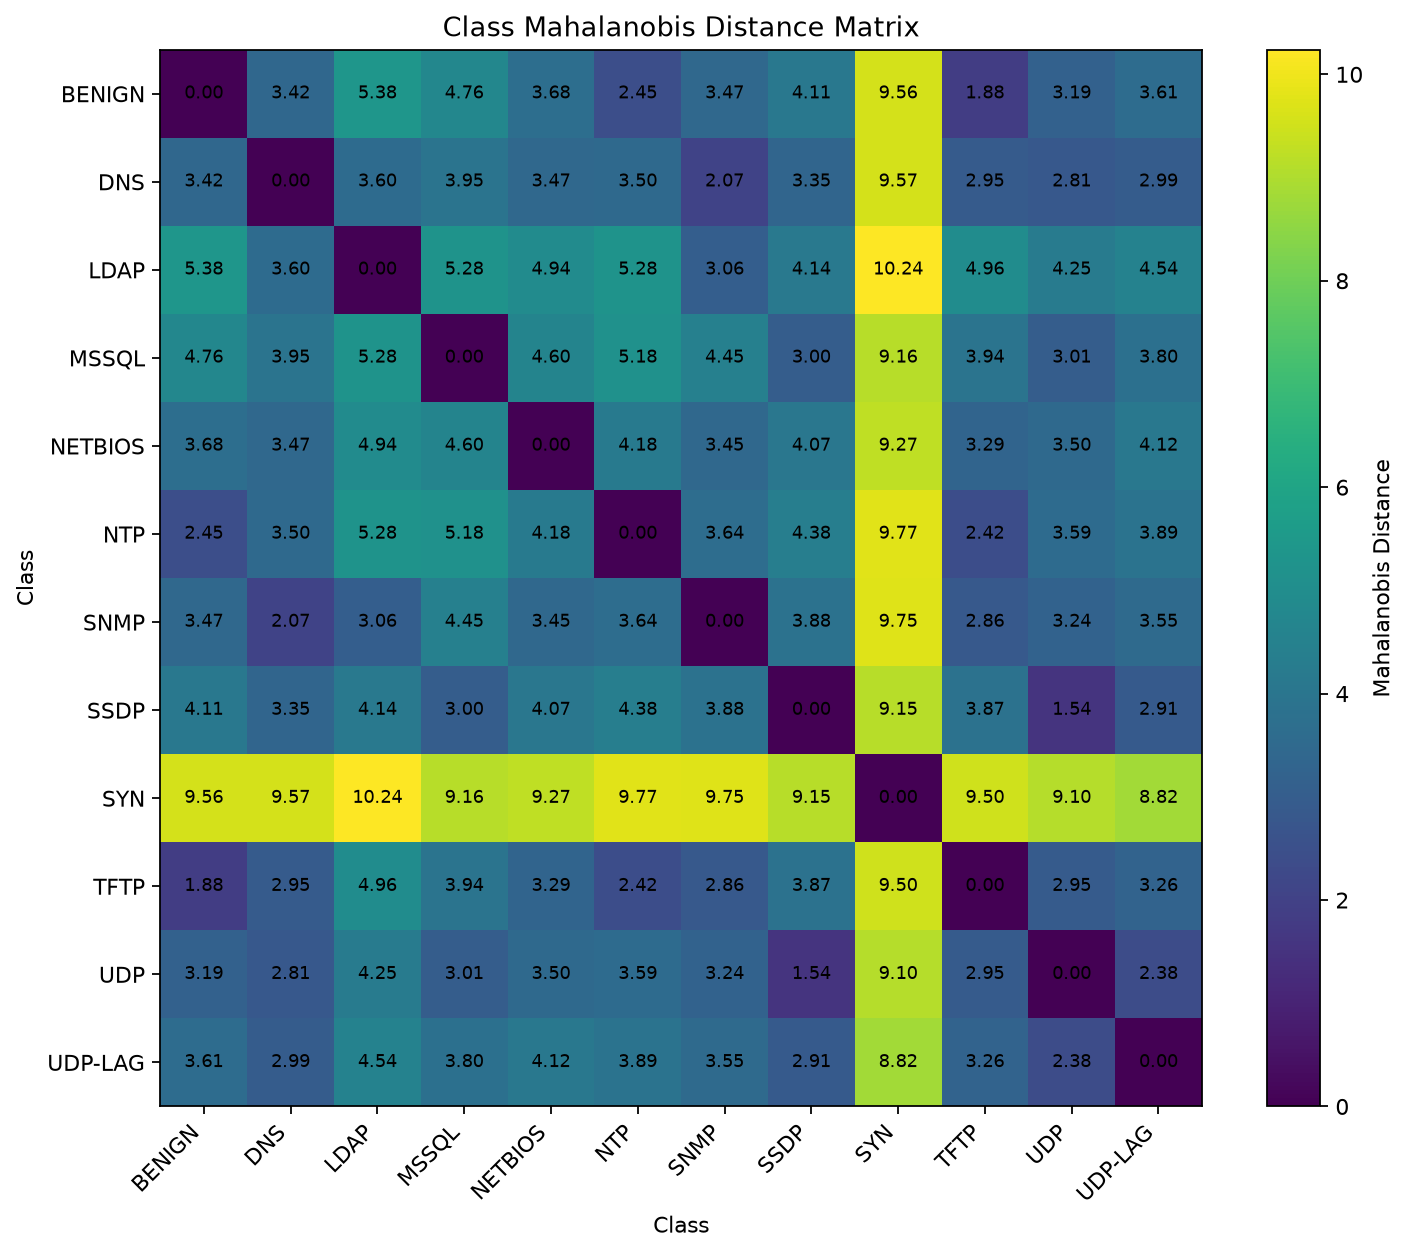

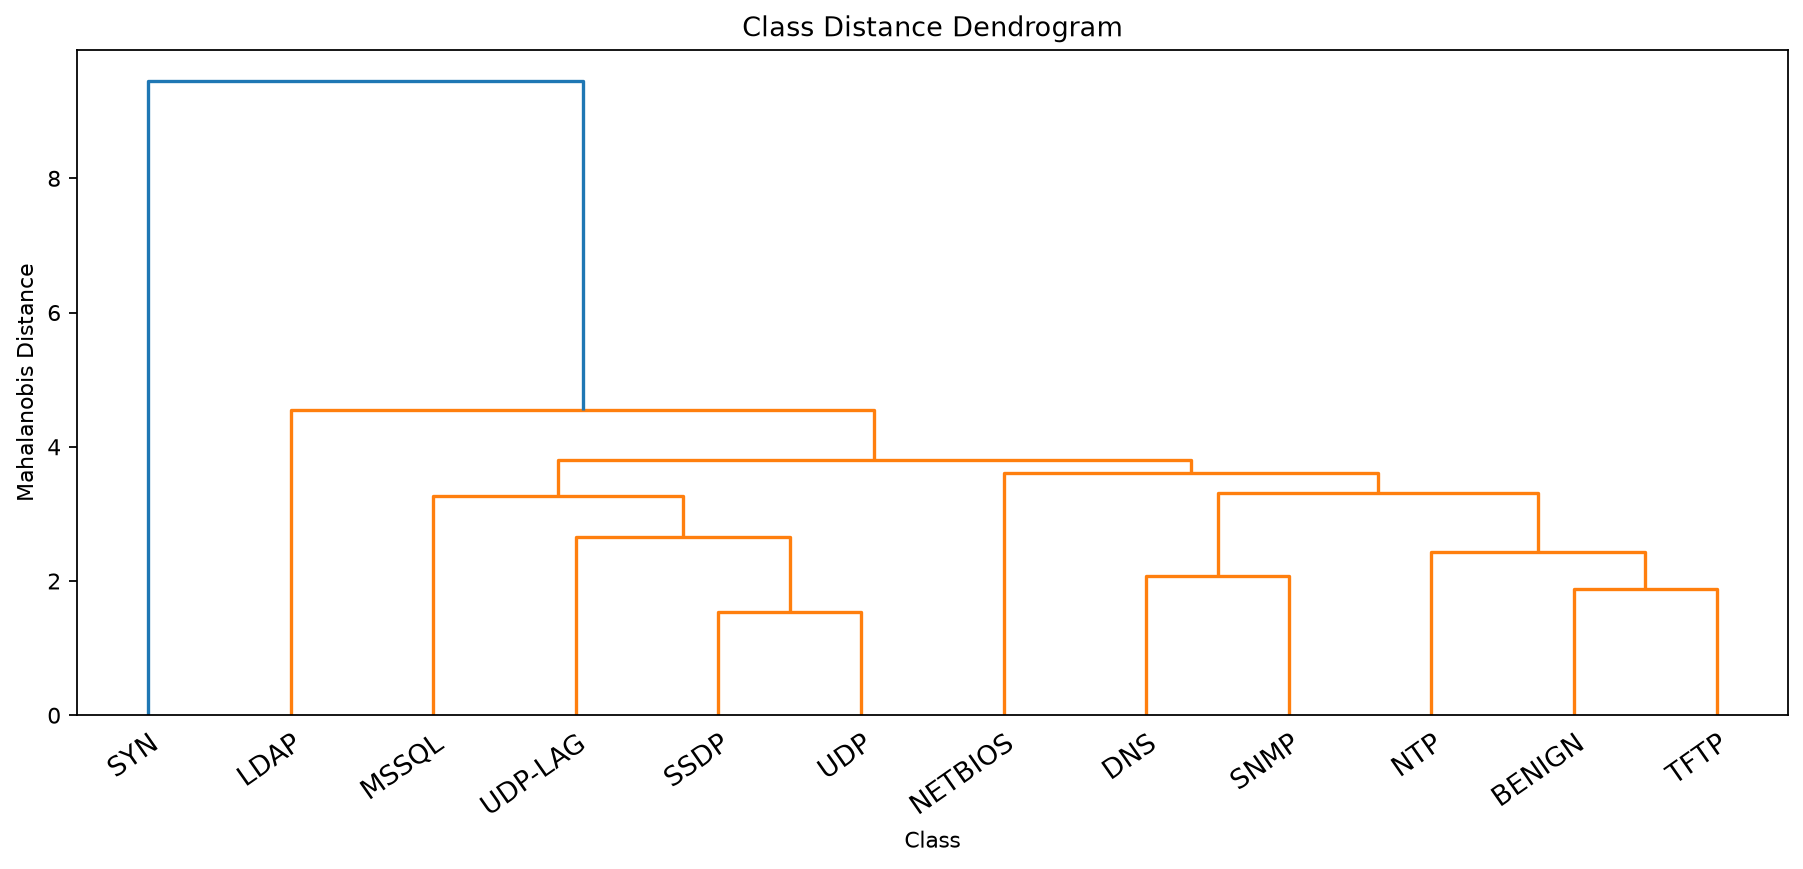

In [8]:
heatmapPath = analysisOutputDirectory / "mahalanobis_distance_heatmap.png"
dendrogramPath = analysisOutputDirectory / "attack_distance_dendrogram.png"
plotDpi = 160
distanceMatrix = pd.read_csv(analysisOutputDirectory / "mahalanobis_distance_matrix.csv", index_col=0)

SimilarityDistanceHeatmapPlot().plot(distanceMatrix, heatmapPath, dpi=plotDpi)
SimilarityDendrogramPlot().plot(distanceMatrix, dendrogramPath, dpi=plotDpi)

display(Image(filename=str(heatmapPath)))
display(Image(filename=str(dendrogramPath)))


### 4.1 PCA Projection of Selected Attacks

Exibe todos os pontos finais translúcidos e seus centroides opacos no espaço de Mahalanobis projetado em três dimensões.


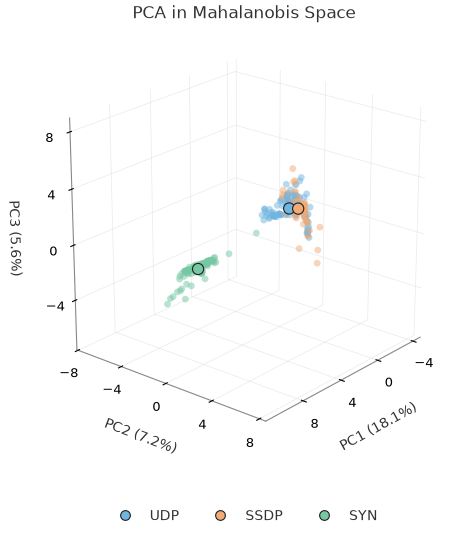

In [3]:
plotOutputPath = analysisOutputDirectory / "attack_samples_pca_3d.png"
plotClasses = ["UDP", "SSDP", "SYN"]  # Edite os ataques; inclua "BENIGN" somente se desejar.
plotPointSize = 24
plotPointAlpha = 0.5
plotCentroidSize = 65
plotCentroidEdgeWidth = 0.8
plotElevation = 22
plotAzimuth = 40
plotDpi = 100
plotTitle = "PCA in Mahalanobis Space"

SimilaritySamples3DPlot().plotFromFile(
    dataPath=plotDataPath, outputPath=plotOutputPath, classes=plotClasses,
    pointSize=plotPointSize, pointAlpha=plotPointAlpha,
    centroidSize=plotCentroidSize, centroidEdgeWidth=plotCentroidEdgeWidth,
    elevation=plotElevation, azimuth=plotAzimuth,
    dpi=plotDpi, title=plotTitle,
)
display(Image(filename=str(plotOutputPath)))


### 4.2 PCA em duas componentes

Exibe PC1 e PC2 da mesma base salva, com ataques selecionáveis e centroides destacados.

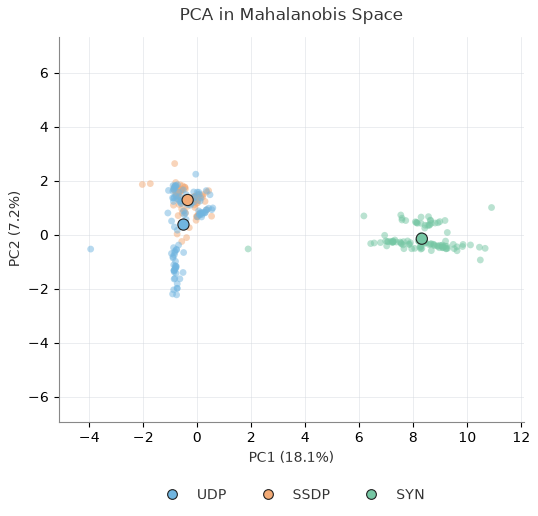

In [4]:
plotOutputPath = analysisOutputDirectory / "attack_samples_pca_2d.png"
plotClasses = ["UDP", "SSDP", "SYN"]  # Edite os ataques; inclua "BENIGN" somente se desejar.
plotPointSize = 24
plotPointAlpha = 0.5
plotCentroidSize = 65
plotCentroidEdgeWidth = 0.8
plotDpi = 100
plotTitle = "PCA in Mahalanobis Space"

SimilaritySamples2DPlot().plotFromFile(
    dataPath=plotDataPath, outputPath=plotOutputPath, classes=plotClasses,
    pointSize=plotPointSize, pointAlpha=plotPointAlpha,
    centroidSize=plotCentroidSize, centroidEdgeWidth=plotCentroidEdgeWidth,
    dpi=plotDpi, title=plotTitle,
)
display(Image(filename=str(plotOutputPath)))


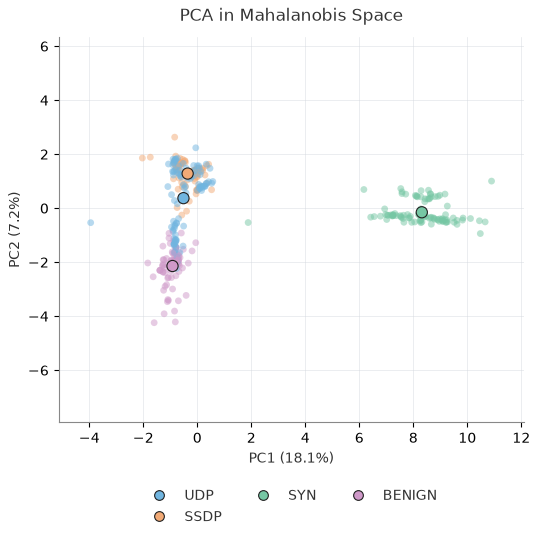

In [5]:
plotOutputPath = analysisOutputDirectory / "attack_samples_pca_2d.png"
plotClasses = ["UDP", "SSDP", "SYN", "BENIGN"]  # Edite os ataques; inclua "BENIGN" somente se desejar.
plotPointSize = 24
plotPointAlpha = 0.5
plotCentroidSize = 65
plotCentroidEdgeWidth = 0.8
plotDpi = 100
plotTitle = "PCA in Mahalanobis Space"

SimilaritySamples2DPlot().plotFromFile(
    dataPath=plotDataPath, outputPath=plotOutputPath, classes=plotClasses,
    pointSize=plotPointSize, pointAlpha=plotPointAlpha,
    centroidSize=plotCentroidSize, centroidEdgeWidth=plotCentroidEdgeWidth,
    dpi=plotDpi, title=plotTitle,
)
display(Image(filename=str(plotOutputPath)))
